## COMP5712M: Programming for Data Science 

## Group project: Data Analysis Project


# Game On: What Makes Steam Games Popular, Well Reviewed and Worth the Price


_Give names and emails of group members here:_

* _Hafsa Hussain_, psks0891@leeds.ac.uk
* , _usernameB_@leeds.ac.uk
* Giridhar Jambunathan, kzbb0899@leeds.ac.uk
* _NameD_, _usernameD_@leeds.ac.uk

In [1]:
%pip install matplotlib openpyxl


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Project Plan

## The Data (10 marks)

Source: Steam Games Dataset from Kaggle ('games.csv') which lists games on steam store with price, release date, genres, tags, review counts and estimated owners.https://www.kaggle.com/datasets/fronkongames/steam-games-dataset

Size (raw): 125,855 games, 39 columns in the file header (40 fields per row)

Accuracy:
-"Estimated owners" is given as a range (e.g. '0-2000') not an exact figure so it's the approximation of popularity. 
-The data was collected around March 2026 so it doesn't include games released after that time so some games have later release dates because they haven't come out yet.

Columns kept (21): App ID, Name, Release date / year / month, Price (USD), Free, Owners (min/max), Positive and Negative reviews, Windows / Mac / Linux support, Deveoplers, Publishers, Genres, Tags, Peak concurrent users, Average playtime, Upcoming/placeholder flag. 


## Project Aim and Objectives (5 marks)

Steam is the largest PC game store, with more than 125,000 games. Every year thousands of new games are released, so it is hard for players to choose what to buy and for developers to know what makes a game succeed. The aim of this project is to use the Steam Games Dataset to understand how the Steam market has grown and what links a game's features to its popularity and player reviews.

The project first cleans the raw data so it can be analysed, then answers three questions: which genres are the most common and best reviewed, whether a game's price affects its reviews and number of owners, and whether a game's success can be predicted before release.

The project mainly uses three types of processing:
 **Visualisation:** charts showing how releases, genres and prices have changed over time.

**Correlation:** finding links between price, genre, publisher type, reviews and owners.

 **Classification:** a model that sorts games into "well reviewed" or "not well reviewed" from their features.

The results could help developers decide on genre and price and help players see whether paying more gets them a better game.

### Specific Objectives

**Objective 1: "Cleaning the Catalogue":** clean and restructure the raw Steam dataset, then chart how the number of games released on Steam has grown over time.

**Objective 2: "Genre Wars":** find which genres and tags dominate Steam, which are growing fastest and which receive the best player reviews.

**Objective 3: "Is It Worth the Price?":** analyse how a game's price relates to its reviews and estimated owners, comparing free-to-play against paid and indie against major publishers.

**Objective 4: "Predicting a Hit":** build a classification model that predicts whether a game will be well reviewed from features such as price, genre, platforms and release year.

## System Design (5 marks)

_Describe your code in terms of the
following two sections._

### Architecture

_Typically this would be  a pipeline in which __data__ goes through several
stages of transformation and analysis, but other architectures are possible.
This does not need to be particularly complicated. A simple diagram with
100-150 words of explanation would
be a good way to present your architecture._
  
### Processing Modules and Algorithms

_Briefly list and describe the most significant computational components of your system and the algorithms you will use to implement them. 
This could include things like:_

Data Cleaning: fix the CSV header, remove duplicates, parse release dates, split owner ranges into min/max, create Yes/No and upcoming flags and log missing values. 

Genre Analysis (Objective 2): split the comma-separated Genres and Tags into one row each with `split` + `explode`, count them with `value_counts`, measure growth with a year-by-genre `crosstab` (2020 vs 2025) and compare positive review % per genre with `groupby` (games with 50+ reviews only).

Pricing Analysis (Objective 3): group games into price bands with `pd.cut`, label publishers as indie or major with a regular expression, summarise each group's median price, median positive % and share of games with 20,000+ owners using one reusable `groupby` function, and measure the link between price and reception with Spearman correlation.

* _combining different datasets_
* _converting samples to a special representation (such as feature vectors)_
* _constructing a special data-structure (such as a decision tree)_
* _running some kind of analysis_

_Your list can be presented in similar form to the one just given, 
but should include a brief
but more specific description of the components and/or algorithms.
Probably three or four components is sufficient for most projects, but
you may want to have more._

# Program Code (15 marks)

_Your code should be divided into relatively short cells, with brief
explanation in markup cells between._

_As noted in the assignment overview, it is not necessary that your coding be
super complex in order to get a good mark. Although there is a mark for
the coding achievement, it is only a quarter of the total._

_The suggested length of the code is about 150 lines for 1 person or 500
for a 4 people project. You should not use more than 500 lines of code._

_You should divide the code in accordance with the specification of modules and/or
algorithms you gave in the previous section. Complex modules should be further
divided into several code cells._

Please note the following about your code:
* <b><i>You may import any packages/modules you wish to use for your project.</i></b> However, for special packages/modules, it would be nice to put comments or a sentence on where these modules are used in the project.


* <b><i>You should submit your notebook in a state where all cells have been
    executed and are displaying the output that you wish to present for grading.</i></b>
    (We will not normally run your code, unless for some reason we wish to check
    that the code functionality matches the given description.)
    
    
* It is strongly suggested you use __function definitions to organise your code__. As well as being generally good programming practice, it will be helpful for easy and flexibily presentation of results visualisations later in the document. In the visualisation sections you will be able to produce images in a concise and flexible way by calling functions defined in the program code secion.

#### _Brief Explanation of following code cell_

Set up: Import the libraries and define file names. The snapshot date is used later to flag upcoming games. 

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

RAW_CSV = "games.csv" if os.path.exists("games.csv") else "../games.csv"   # raw file may sit one folder up
CLEAN_CSV = "steam_games_clean.csv"


SNAPSHOT_DATE = pd.Timestamp("2026-03-31")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)

Load raw data and fix header. The header row in the original CSV is wrong, it has one fewer name than there are columns of data. Discount and DLC count were joined into one name DiscountDLC count. If it was loaded as is then every column after that would be labelled with the wrong name. 

In [3]:
RAW_COLUMNS = [
    "AppID", "Name", "Release date", "Estimated owners", "Peak CCU", "Required age",
    "Price", "Discount", "DLC count", "About the game", "Supported languages",
    "Full audio languages", "Reviews", "Header image", "Website", "Support url",
    "Support email", "Windows", "Mac", "Linux", "Metacritic score", "Metacritic url",
    "User score", "Positive", "Negative", "Score rank", "Achievements", "Recommendations",
    "Notes", "Average playtime forever", "Average playtime two weeks",
    "Median playtime forever", "Median playtime two weeks", "Developers", "Publishers",
    "Categories", "Genres", "Tags", "Screenshots", "Movies",
]


KEEP = {
    "AppID": "App ID", "Name": "Name", "Release date": "Release date",
    "Price": "Price (USD)", "Estimated owners": "Estimated owners",
    "Positive": "Positive reviews", "Negative": "Negative reviews",
    "Windows": "Windows", "Mac": "Mac", "Linux": "Linux",
    "Developers": "Developers", "Publishers": "Publishers",
    "Genres": "Genres", "Tags": "Tags",
    "Peak CCU": "Peak concurrent users", "Average playtime forever": "Avg playtime (minutes)",
}


raw = pd.read_csv(RAW_CSV, header=0, names=RAW_COLUMNS, usecols=list(KEEP), low_memory=False)
raw_rows = len(raw)
print(f"Raw rows in file: {raw_rows:,}")

df = raw.rename(columns=KEEP)
df.head()

Raw rows in file: 125,855


,App ID,Name,Release date,Estimated owners,Peak concurrent users,Price (USD),Windows,Mac,Linux,Positive reviews,Negative reviews,Avg playtime (minutes),Developers,Publishers,Genres,Tags
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0.00,True,False,False,0,0,0,NaN,NaN,NaN,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,5.24,True,False,False,252,3,8,minori,MangaGamer,Adventure,"Adventure,Visual Novel,Anime,Cute"
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,4.99,True,True,False,21,3,0,Somer Games,8floor,Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec..."
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,8.99,True,False,False,0,0,0,유진게임즈,유진게임즈,"Casual,Indie,Simulation",NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,4.99,True,False,False,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Action,Early Access",NaN


Remove duplicates and parse release dates. Delete repeated App IDs and store release dates as text (e.g. 'Oct 21, 2008)

In [4]:

before = len(df)
df = df.drop_duplicates(subset="App ID")
dupes_removed = before - len(df)


df["Release date"] = pd.to_datetime(df["Release date"], format="mixed", errors="coerce")
bad_dates = int(df["Release date"].isna().sum())
df = df.dropna(subset=["Release date"])

df["Release year"] = df["Release date"].dt.year
df["Release month"] = df["Release date"].dt.month

print("Duplicate App IDs removed:", dupes_removed)
print("Rows dropped for unreadable release date:", bad_dates)
print("Date range:", df["Release date"].min().date(), "to", df["Release date"].max().date())

Duplicate App IDs removed: 0
Rows dropped for unreadable release date: 0
Date range: 1997-06-30 to 2026-12-01


Restructure Columns:
 Estimated Owners, Free, Windows / Mac / Linux, Upcoming / placeholder, Genres and Tags

In [5]:

owners = df["Estimated owners"].str.split(" - ", expand=True)
df["Owners (min)"] = pd.to_numeric(owners[0], errors="coerce").astype("Int64")
df["Owners (max)"] = pd.to_numeric(owners[1], errors="coerce").astype("Int64")


df["Free"] = (df["Price (USD)"] == 0).map({True: "Yes", False: "No"})


for col in ["Windows", "Mac", "Linux"]:
    df[col] = df[col].astype(bool).map({True: "Yes", False: "No"})


df["Upcoming / placeholder"] = (df["Release date"] > SNAPSHOT_DATE).map({True: "Yes", False: "No"})


ORDER = ["App ID", "Name", "Release date", "Release year", "Release month", "Price (USD)",
         "Free", "Owners (min)", "Owners (max)", "Positive reviews", "Negative reviews",
         "Windows", "Mac", "Linux", "Developers", "Publishers", "Genres", "Tags",
         "Peak concurrent users", "Avg playtime (minutes)", "Upcoming / placeholder"]
df = df[ORDER].reset_index(drop=True)
df.head()

,App ID,Name,Release date,Release year,Release month,Price (USD),Free,Owners (min),Owners (max),Positive reviews,Negative reviews,Windows,Mac,Linux,Developers,Publishers,Genres,Tags,Peak concurrent users,Avg playtime (minutes),Upcoming / placeholder
0,2539430,Black Dragon Mage Playtest,2023-08-01,2023,8,0.00,Yes,0,0,0,0,Yes,No,No,NaN,NaN,NaN,NaN,0,0,No
1,496350,Supipara - Chapter 1 Spring Has Come!,2016-07-29,2016,7,5.24,No,0,20000,252,3,Yes,No,No,minori,MangaGamer,Adventure,"Adventure,Visual Novel,Anime,Cute",0,8,No
2,1034400,Mystery Solitaire The Black Raven,2019-05-06,2019,5,4.99,No,0,20000,21,3,Yes,Yes,No,Somer Games,8floor,Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",0,0,No
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,2024-10-31,2024,10,8.99,No,0,20000,0,0,Yes,No,No,유진게임즈,유진게임즈,"Casual,Indie,Simulation",NaN,1,0,No
4,3631080,Maze Quest VR,2025-04-24,2025,4,4.99,No,0,20000,0,0,Yes,No,No,Reality Expanded LLC,Reality Expanded LLC,"Action,Early Access",NaN,0,0,No


Some games are missing details like developer or tags. Those are left blank instead of guessing. The log shows what was checked and found.

In [6]:
cleaning_log = pd.DataFrame({
    "Check": [
        "Raw rows in file",
        "Rows after cleaning",
        "Duplicate App IDs removed",
        "Rows dropped for unreadable release date",
        "Games with no name",
        "Games with no developer listed",
        "Games with no publisher listed",
        "Games with no genre listed",
        "Games with no tags listed",
        "Games flagged upcoming/placeholder (release date after 31 Mar 2026)",
        "Games with owners '0 - 0' (no ownership estimate)",
        "Free games (price = 0)",
    ],
    "Count": [
        raw_rows,
        len(df),
        dupes_removed,
        bad_dates,
        df["Name"].isna().sum(),
        df["Developers"].isna().sum(),
        df["Publishers"].isna().sum(),
        df["Genres"].isna().sum(),
        df["Tags"].isna().sum(),
        (df["Upcoming / placeholder"] == "Yes").sum(),
        (df["Owners (max)"] == 0).sum(),
        (df["Free"] == "Yes").sum(),
    ],
})
cleaning_log["Count"] = cleaning_log["Count"].map("{:,}".format)
cleaning_log

,Check,Count
0,Raw rows in file,"125,855"
1,Rows after cleaning,"125,855"
2,Duplicate App IDs removed,0
3,Rows dropped for unreadable release date,0
4,Games with no name,1
5,Games with no developer listed,"8,449"
6,Games with no publisher listed,"8,922"
7,Games with no genre listed,"8,423"
8,Games with no tags listed,"42,502"
9,Games flagged upcoming/placeholder (release da...,3


Count games per year and set up the chart. How many games were released each year will leave out the games that aren't out yet. The chart code is written here and used later in results.

In [7]:
released = df[df["Upcoming / placeholder"] == "No"]
per_year = released.groupby("Release year").size()

def plot_games_per_year(per_year):
    fig, ax = plt.subplots(figsize=(11, 5))
    colors = ["#2b6cb0"] * len(per_year)
    colors[-1] = "#9dc0e6"          
    ax.bar(per_year.index, per_year.values, color=colors)
    ax.set_title("Games released on Steam per year (1997-2026)", fontsize=14)
    ax.set_xlabel("Release year")
    ax.set_ylabel("Number of games released")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.spines[["top", "right"]].set_visible(False)
    for yr in [2025, 2026]:
        ax.annotate(f"{per_year[yr]:,}", (yr, per_year[yr]), ha="center", va="bottom", fontsize=9)
    ax.text(2026, per_year.max() * 0.45, "2026: Jan-Mar only", rotation=90,
            ha="center", va="center", fontsize=9, color="#555555")
    plt.tight_layout()
    plt.show()

per_year.loc[[2006, 2010, 2014, 2018, 2020, 2022, 2024, 2025, 2026]].to_frame("Games released")

,Games released
Release year,
2006,69
2010,255
2014,1523
2018,7461
2020,8804
2022,12288
2024,20033
2025,24973
2026,3313


### Objective 2: Genre Wars - Popularity and Reception by Genre

#### Brief Explanation of following code cell

Load the cleaned dataset. Objective 2 uses the cleaned data saved in the Excel file `Steam Games Dataset.xlsx` (sheet "Games"). `pd.read_excel` needs the `openpyxl` module, which is installed at the top of the notebook. Games that are not out yet (upcoming/placeholder) are removed.

In [8]:
EXCEL_FILE = "Steam Games Dataset.xlsx"

games = pd.read_excel(EXCEL_FILE, sheet_name="Games")
games = games[games["Upcoming / placeholder"] == "No"]   # keep only games that have been released

print("Games loaded:", len(games))
games[["Name", "Release year", "Genres", "Tags", "Positive reviews", "Negative reviews"]].head()

Games loaded: 125852


,Name,Release year,Genres,Tags,Positive reviews,Negative reviews
0,Carmageddon Max Pack,1997,"Action,Indie,Racing","Combat Racing,Racing,Gore,Action,Classic,Indie...",837,106
1,POSTAL,1997,"Action,Indie","Horror,Villain Protagonist,Psychological Horro...",10023,1000
2,Half-Life,1998,Action,"FPS,Classic,1990's,Singleplayer,Sci-fi,Multipl...",143086,5135
3,Team Fortress Classic,1999,Action,"Action,FPS,Multiplayer,Classic,Hero Shooter,Sh...",7602,1136
4,Half-Life: Opposing Force,1999,Action,"FPS,Action,Classic,Sci-fi,Singleplayer,Shooter...",24363,1198


#### Brief Explanation of following code cell

Split genres and tags into separate rows. One game can have several genres stored as one piece of text, e.g. `"Action,Indie,Racing"`. `str.split(",")` turns the text into a list and `explode()` gives each genre its own row, so a game with 3 genres appears 3 times. The same is done for tags. Games with no genre or no tags are skipped.

In [9]:
genre_rows = games.dropna(subset=["Genres"]).copy()
genre_rows["Genre"] = genre_rows["Genres"].str.split(",")
genre_rows = genre_rows.explode("Genre")

tag_rows = games.dropna(subset=["Tags"]).copy()
tag_rows["Tag"] = tag_rows["Tags"].str.split(",")
tag_rows = tag_rows.explode("Tag")

print("Rows after splitting genres:", len(genre_rows))
print("Rows after splitting tags:  ", len(tag_rows))
genre_rows[["Name", "Genre"]].head(6)

Rows after splitting genres: 338573
Rows after splitting tags:   1180141


,Name,Genre
0,Carmageddon Max Pack,Action
0,Carmageddon Max Pack,Indie
0,Carmageddon Max Pack,Racing
1,POSTAL,Action
1,POSTAL,Indie
2,Half-Life,Action


#### Brief Explanation of following code cell

Find the most common genres and tags. `value_counts()` counts how many games have each genre and tag. The 10 biggest genres are saved in `top_genres` and used for the rest of Objective 2.

In [10]:
genre_counts = genre_rows["Genre"].value_counts()
tag_counts = tag_rows["Tag"].value_counts()

top_genres = genre_counts.head(10).index

top_genre_table = genre_counts.head(10).to_frame("Number of games")
top_genre_table["% of all games"] = (top_genre_table["Number of games"] / len(games) * 100).round(1)
top_genre_table

,Number of games,% of all games
Genre,,
Indie,82881,65.9
Casual,51677,41.1
Action,47343,37.6
Adventure,46292,36.8
Simulation,24911,19.8
Strategy,23056,18.3
RPG,21576,17.1
Free To Play,12605,10.0
Early Access,11571,9.2


#### Comment on previous cell output

Indie is on about two thirds of all games. The percentages add up to more than 100% because most games have more than one genre.

#### Brief Explanation of following code cell

Find which genres are growing fastest. `pd.crosstab` counts the games released each year for each of the top 10 genres. Growth is the percentage change in releases between 2020 and 2025, the last full year in the data:

Growth (%) = (games in 2025 - games in 2020) / games in 2020 x 100

In [11]:
recent = genre_rows[genre_rows["Genre"].isin(top_genres) & genre_rows["Release year"].between(2015, 2025)]
genre_by_year = pd.crosstab(recent["Release year"], recent["Genre"])

growth_table = pd.DataFrame({
    "Games in 2020": genre_by_year.loc[2020],
    "Games in 2025": genre_by_year.loc[2025],
})
growth_table["Growth (%)"] = ((growth_table["Games in 2025"] - growth_table["Games in 2020"])
                              / growth_table["Games in 2020"] * 100).round(1)
growth_table = growth_table.sort_values("Growth (%)", ascending=False)
growth_table

,Games in 2020,Games in 2025,Growth (%)
Genre,,,
Free To Play,850,3007,253.8
Early Access,787,2608,231.4
Simulation,1821,5275,189.7
RPG,1532,4228,176.0
Strategy,1688,4445,163.3
Casual,3887,10120,160.4
Adventure,3495,8372,139.5
Indie,6553,15383,134.7
Action,3701,8027,116.9


#### Brief Explanation of following code cell

Compare player reviews by genre. For each game, the positive score is the share of its reviews that are positive:

Positive % = positive reviews / (positive + negative reviews) x 100

Only games with at least 50 reviews are used. Without this rule, a game with just one positive review would score 100% and skew the averages. Each genre's average (mean) and median positive score are then worked out with `groupby`.

In [12]:
MIN_REVIEWS = 50

genre_rows["Total reviews"] = genre_rows["Positive reviews"] + genre_rows["Negative reviews"]
reviewed = genre_rows[(genre_rows["Total reviews"] >= MIN_REVIEWS) & genre_rows["Genre"].isin(top_genres)].copy()
reviewed["Positive %"] = reviewed["Positive reviews"] / reviewed["Total reviews"] * 100

print("Games with at least", MIN_REVIEWS, "reviews:", reviewed["App ID"].nunique())

review_table = reviewed.groupby("Genre").agg(
    Games=("Name", "count"),
    Average_positive=("Positive %", "mean"),
    Median_positive=("Positive %", "median"),
).round(1).sort_values("Average_positive", ascending=False)
review_table.columns = ["Games (50+ reviews)", "Average positive %", "Median positive %"]
review_table

Games with at least 50 reviews: 30176


,Games (50+ reviews),Average positive %,Median positive %
Genre,,,
Casual,10254,79.6,83.4
Adventure,13191,79.1,82.5
Indie,21075,79.0,82.5
RPG,6838,77.9,80.7
Action,12856,77.2,80.4
Strategy,6675,76.5,79.5
Simulation,7343,76.3,79.6
Free To Play,2671,76.2,78.9
Sports,1320,76.1,79.2


#### Brief Explanation of following code cell

Define the chart functions for Objective 2. The functions are only defined here. They are called in the Objective 2 results section below.
* `plot_top_counts`: horizontal bar chart of the most common genres or tags
* `plot_genre_growth`: horizontal bar chart of each genre's growth from 2020 to 2025
* `plot_genre_reviews`: box plot of positive review % for each genre

In [13]:
def plot_top_counts(counts, n, title, colour="#2b6cb0"):
    top = counts.head(n).sort_values()          # sort so the biggest bar is at the top
    fig, ax = plt.subplots(figsize=(10, 0.45 * n + 1))
    bars = ax.barh(top.index, top.values, color=colour)
    ax.bar_label(bars, labels=[f"{v:,}" for v in top.values], padding=3, fontsize=9)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Number of games")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


def plot_genre_growth(growth_table):
    data = growth_table["Growth (%)"].sort_values()
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(data.index, data.values, color="#2f855a")
    ax.bar_label(bars, labels=[f"+{v:.0f}%" for v in data.values], padding=3, fontsize=9)
    ax.set_title("Growth in games released per genre, 2020 to 2025", fontsize=14)
    ax.set_xlabel("Increase in number of games released (%)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


def plot_genre_reviews(reviewed):
    order = reviewed.groupby("Genre")["Positive %"].median().sort_values(ascending=False).index
    data = [reviewed.loc[reviewed["Genre"] == g, "Positive %"] for g in order]
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.boxplot(data, showfliers=False)               # outliers hidden to keep the chart readable
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels(order, rotation=30, ha="right")
    ax.set_title("Positive review % by genre (games with 50+ reviews)", fontsize=14)
    ax.set_ylabel("Positive reviews (%)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

### Objective 3: Is It Worth the Price? - Price vs. Popularity

#### Explanation of code cell

Prepare the data for Objective 3, using the `games` table from Objective 2.
* **Price band:** `pd.cut` sorts each game into a price group: Free, $0.01-4.99, $5-9.99, $10-19.99, $20-39.99 or $40+.
* **Publisher type:** a game is **Major publisher** if its publisher is one of 16 big companies (Ubisoft, EA, SEGA, Valve), and **Indie** if it has the Indie genre and is not from a major publisher.
* **Positive %:** the same as in Objective 2, using only games with at least 50 reviews.
* **Owners:** owners are only given as ranges, so we measure the share of games with **20,000+ owners**. Games with no owner estimate ("0 - 0") are left out.

In [14]:
MAJOR_PUBLISHERS = (r"\b(?:Ubisoft|Electronic Arts|Square Enix|SEGA|Bandai Namco|Activision|2K|Bethesda|"
                    r"Capcom|Konami|Koei Tecmo|Warner Bros|Xbox Game Studios|PlayStation Publishing|Rockstar Games|Valve)\b")
PRICE_BINS = [-0.01, 0, 4.99, 9.99, 19.99, 39.99, float("inf")]
PRICE_LABELS = ["Free", "$0.01-4.99", "$5-9.99", "$10-19.99", "$20-39.99", "$40+"]

prices = games.copy()
prices["Price band"] = pd.cut(prices["Price (USD)"], bins=PRICE_BINS, labels=PRICE_LABELS)
prices["20k+ owners"] = prices["Owners (min)"] >= 20000

is_major = prices["Publishers"].str.contains(MAJOR_PUBLISHERS, case=False, regex=True, na=False)
is_indie = prices["Genres"].str.contains("Indie", na=False)
prices["Publisher type"] = None
prices.loc[is_indie & ~is_major, "Publisher type"] = "Indie"
prices.loc[is_major, "Publisher type"] = "Major publisher"

prices["Total reviews"] = prices["Positive reviews"] + prices["Negative reviews"]
rated = prices[prices["Total reviews"] >= MIN_REVIEWS].copy()      # games with enough reviews to score
rated["Positive %"] = rated["Positive reviews"] / rated["Total reviews"] * 100
owned = prices[prices["Owners (max)"] > 0]                        # games with an owner estimate

print("Games with 50+ reviews:   ", len(rated))
print("Games with owner estimate:", len(owned))
prices["Publisher type"].value_counts()

Games with 50+ reviews:    30624
Games with owner estimate: 101276


Publisher type
Indie              82831
Major publisher     1437
Name: count, dtype: int64

#### Explanation of the code cell

`reception_table` groups the games by any column and returns, for each group: the number of games, the median price, the median positive review % and the % of games with 20,000+ owners. The median is used for price and reviews because a few very expensive or very popular games would get the average up. Writing this once as a function means the same measures are used for every comparison.
Paid games have a slightly higher median review score than free-to-play games, but free-to-play games are more likely to reach 20,000+ owners.

In [15]:
def reception_table(group_col):
    groups = prices.groupby(group_col, observed=True)
    table = pd.DataFrame({
        "Games": groups.size(),
        "Median price ($)": groups["Price (USD)"].median(),
        "Games (50+ reviews)": rated.groupby(group_col, observed=True).size(),
        "Median positive %": rated.groupby(group_col, observed=True)["Positive %"].median(),
        "% with 20k+ owners": owned.groupby(group_col, observed=True)["20k+ owners"].mean() * 100,
    })
    return table.round(1)


free_paid_table = reception_table("Free").rename(index={"Yes": "Free-to-play", "No": "Paid"})
free_paid_table = free_paid_table.loc[["Free-to-play", "Paid"]]
free_paid_table

,Games,Median price ($),Games (50+ reviews),Median positive %,% with 20k+ owners
Free,,,,,
Free-to-play,26658,0.0,4062,79.2,39.0
Paid,99194,3.6,26562,82.4,23.8


#### Explanation of code cell

Compare the price bands and measure the link between price and reception. As well as the table, the **Spearman correlation** is worked out for paid games only. Spearman compares the *ranks* of the values rather than the values themselves, so it is not thrown off by a few games priced at hundreds of dollars or by the owner figures being ranges. It goes from -1 to +1, and a value near 0 means there is no link.

In [16]:
price_band_table = reception_table("Price band")

paid_rate = rated[rated["Free"] == "No"]
paid_owned = owned[owned["Free"] == "No"]
price_vs_reviews = paid_rate["Price (USD)"].corr(paid_rate["Positive %"], method="spearman")
price_vs_owners = paid_owned["Price (USD)"].corr(paid_owned["Owners (min)"], method="spearman")

print(f"Spearman correlation, price vs positive %: {price_vs_reviews:.2f}")
print(f"Spearman correlation, price vs owners:     {price_vs_owners:.2f}")
price_band_table

Spearman correlation, price vs positive %: 0.14
Spearman correlation, price vs owners:     0.02


,Games,Median price ($),Games (50+ reviews),Median positive %,% with 20k+ owners
Price band,,,,,
Free,26658,0.0,4062,79.2,39.0
$0.01-4.99,66768,2.0,16155,81.1,23.3
$5-9.99,20096,7.8,5915,84.7,23.6
$10-19.99,9746,15.0,3643,84.0,26.9
$20-39.99,1802,27.5,717,82.5,28.9
$40+,782,70.0,132,75.8,12.9


#### Explanation of code cell

Compare indie games with games from major publishers, using the same `reception_table` function.

In [17]:
publisher_table = reception_table("Publisher type")
publisher_table

,Games,Median price ($),Games (50+ reviews),Median positive %,% with 20k+ owners
Publisher type,,,,,
Indie,82831,2.5,21033,82.5,24.0
Major publisher,1437,6.0,1255,83.0,84.7


#### Explanation of code cell

Define the chart functions for Objective 3. They are called in the Objective 3 results section below.
* `plot_price_band_reviews`: box plot of positive review % for each price band
* `plot_price_band_owners`: bar chart of the % of games in each price band with 20,000+ owners
* `plot_group_comparison`: two side-by-side bar charts comparing free-to-play vs paid and indie vs major publishers on reviews and owners

Matplotlib reads text between two `$` signs as a maths formula, so the `$` in the price labels is escaped with `\$`.

In [18]:
def plot_price_band_reviews(rated):
    data = [rated.loc[rated["Price band"] == band, "Positive %"] for band in PRICE_LABELS]
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.boxplot(data, showfliers=False)           
    ax.set_xticks(range(1, len(PRICE_LABELS) + 1))
    ax.set_xticklabels([label.replace("$", r"\$") for label in PRICE_LABELS])
    ax.set_title("Positive review % by price band (games with 50+ reviews)", fontsize=14)
    ax.set_xlabel("Price band (USD)")
    ax.set_ylabel("Positive reviews (%)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


def plot_price_band_owners(price_band_table):
    data = price_band_table["% with 20k+ owners"]
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar([label.replace("$", r"\$") for label in data.index], data.values, color="#2b6cb0")
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in data.values], padding=3, fontsize=9)
    ax.set_title("Share of games with 20,000+ owners by price band", fontsize=14)
    ax.set_xlabel("Price band (USD)")
    ax.set_ylabel("Games with 20,000+ owners (%)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


def plot_group_comparison(free_paid_table, publisher_table):
    both = pd.concat([free_paid_table, publisher_table])
    colours = ["#dd6b20", "#2b6cb0", "#2f855a", "#6b46c1"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, col in zip(axes, ["Median positive %", "% with 20k+ owners"]):
        bars = ax.bar(both.index, both[col], color=colours)
        ax.bar_label(bars, labels=[f"{v:.1f}%" for v in both[col]], padding=3, fontsize=9)
        ax.set_title(col, fontsize=13)
        ax.set_ylim(0, 100)
        ax.tick_params(axis="x", rotation=15)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("Free-to-play vs paid and indie vs major publishers", fontsize=14)
    plt.tight_layout()
    plt.show()

#### _Comment on previous cell output (optional)_

_As well as describing code, it will in many cases be informative to describe the output
that has been generated by a cell._

_The previous output cell shows a key number in our fridge magnet analysis._

#### _Brief Explanation of following code cell_

_Since fridge magnets often take the form of cute animals, we use `pandas` to convert the raw data into a `DataFrame`._

#### _Comment on previous cell output (optional)_
_The output from the previous cell is very interesting._

_The following cell defines a visualisation function for the data._

In [19]:
def fridge_sorted_bar(color='blue'):
    df.sort_values(0).plot.bar( color=color)   

###  _More code cells_
_You can add as many code cells as you require, but it is
recommended that you break code into relatively small chunks and
do not exceed the maximum number of lines stated above._

# Project Outcome (10 + 10 marks)

The number of games released on Steam each year has grown from little before 2006 reaching up to 25,000 in 2025. The raw data shows 125,855 games with no duplicate or unreadable dates. Some are missing details like developer, publisher, genre or tags. 

_This section should describe the outcome of the project by means of both explanation of the results and by graphical visualisation in the form of graphs, charts or or other kinds of diagram_

_The section should begin with a general overview of the results and then have a section for each of the project objectives. For each of these objectives an explanation of more specific results relating to that objective shoud be given, followed by a section presenting some visualisation of the results obtained. (In the case where
the project had just one objective, you should still have a section describing
the results from a general perspective followed by a section that focuses on
the particular objective.)_

_The marks for this section will be divided into 10 marks for Explanation
and 10 marks for Visualisation. These marks will be awarded for the Project Outcome
section as a whole, not for each objective individually. Hence, you do not
have to pay equal attention to each. However, you are expected to have a
some explanation and visualisation for each. It is suggested you have
200-400 words explanation for each objective._






## Overview of Results
_Give a general overview of the results (around 200 words)._

## Objective 1

### Explanation of Results
The raw file has 125,855 games with no duplicates and no release dates that couldn't be read. Many games had missing details: 8,449 with no developer, 8,922 with no publisher, 8,423 with no genre and 42,502 with no tags. Those are left blank. Three games have release dates after the data was collected so they are marked as upcoming and left out of yearly counts.

The chart shows a very slow start before 2006 because Steam added fewer games than 10 per year. Releases grew from 69 in 2006 to 468 in 2013 and tripled to 1,523 in 2014. Reaching to 4,141 in 2016 and 7,461 in 2018. Releases rose with 12,288 in 2022, 20,033 in 2024 and 24,973 in 2025. Three times the amount released in 2020. 2026 isn't fully complete because it only shows games that came out from January to the end of March 2026. 

_200-400 words_

### Visualisation
The bar chart shows the number of games released on Steam each year. 2026 is shown in a lighter colour because the data only covers January to March. 

In [20]:
cleaning_log

,Check,Count
0,Raw rows in file,"125,855"
1,Rows after cleaning,"125,855"
2,Duplicate App IDs removed,0
3,Rows dropped for unreadable release date,0
4,Games with no name,1
5,Games with no developer listed,"8,449"
6,Games with no publisher listed,"8,922"
7,Games with no genre listed,"8,423"
8,Games with no tags listed,"42,502"
9,Games flagged upcoming/placeholder (release da...,3


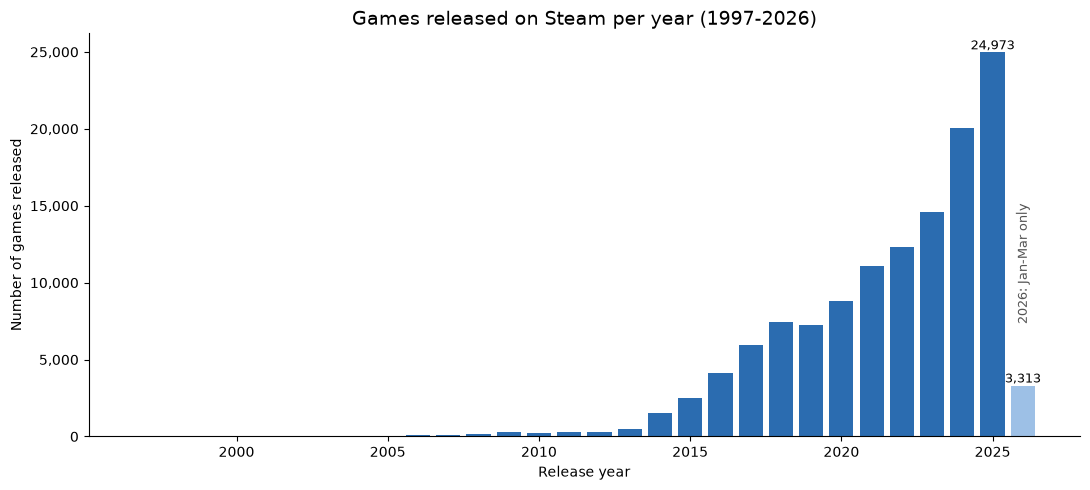

In [21]:
plot_games_per_year(per_year)

## Objective 2
### Explanation of Results

Objective 2 looks at which genres and tags are most common on Steam, which genres are growing fastest and which get the best player reviews. Most games have more than one genre, so a game can be counted in several genres.

**Which genres dominate?** Indie is by far the biggest genre. 82,881 games (65.9% of all released games) are labelled Indie. Casual (51,677), Action (47,343) and Adventure (46,292) come next, followed by Simulation, Strategy and RPG, which each have more than 20,000 games. Sports is the smallest of the top 10 with 4,971 games. Steam also lists "Free To Play" and "Early Access" as genres, even though they describe how a game is sold rather than what kind of game it is. The tags show a similar picture. "Singleplayer" is the most used tag (50,353 games), followed by Indie, Action, Casual and Adventure. Art-style tags such as 2D, 3D, Pixel Graphics and Colorful are also near the top.

**Which genres are growing fastest?** Every top genre had more releases in 2025 than in 2020. Free To Play (+253.8%) and Early Access (+231.4%) grew the fastest, which suggests more developers are releasing games for free or before they are finished. Simulation (+189.7%) and RPG (+176.0%) were next. Action (+116.9%) and Sports (+92.8%) grew the slowest, but even they roughly doubled.

**Which genres get the best reviews?** Only the 30,176 games with at least 50 reviews were used. Casual has the highest average positive score (79.6%), just ahead of Adventure (79.1%) and Indie (79.0%). Early Access has the lowest (74.1%), probably because these games are unfinished and players review bugs or missing content. However, the gap between the best and worst genre is only about 5.5 percentage points and every median is between 77% and 84%. Genre on its own therefore makes only a small difference to how well a game is reviewed. The box plot shows that every genre has a wide spread of scores.

The table below brings together each top genre's size, growth and average review score.

In [22]:
summary = top_genre_table.join(growth_table["Growth (%)"]).join(review_table["Average positive %"])
summary

,Number of games,% of all games,Growth (%),Average positive %
Genre,,,,
Indie,82881,65.9,134.7,79.0
Casual,51677,41.1,160.4,79.6
Action,47343,37.6,116.9,77.2
Adventure,46292,36.8,139.5,79.1
Simulation,24911,19.8,189.7,76.3
Strategy,23056,18.3,163.3,76.5
RPG,21576,17.1,176.0,77.9
Free To Play,12605,10.0,253.8,76.2
Early Access,11571,9.2,231.4,74.1


### Visualisation

**Most common genres.** Indie stands out, with Casual, Action and Adventure well behind.

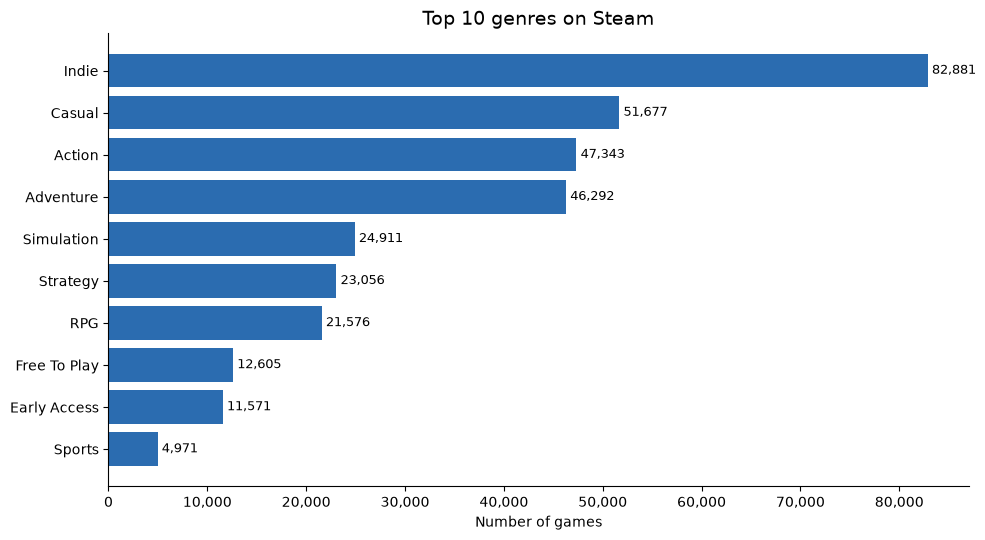

In [23]:
plot_top_counts(genre_counts, 10, "Top 10 genres on Steam")

**Most common tags.** Tags are more detailed than genres. Singleplayer is the most used tag, and art-style tags (2D, 3D, Pixel Graphics, Colorful) are also popular.

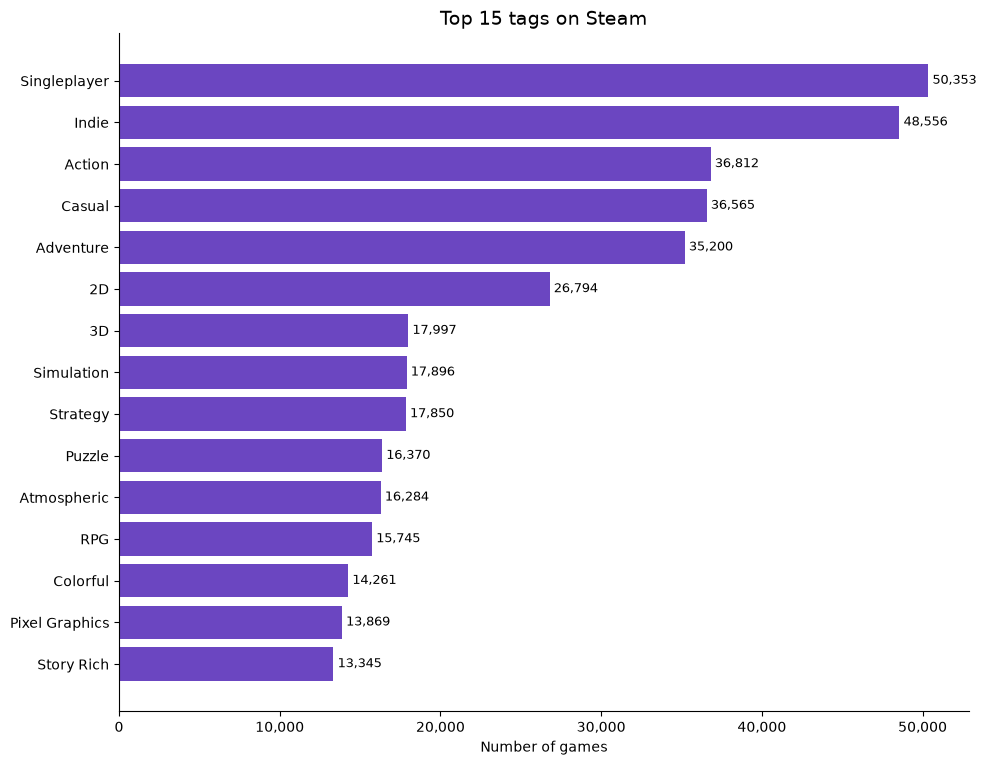

In [24]:
plot_top_counts(tag_counts, 15, "Top 15 tags on Steam", colour="#6b46c1")

**Fastest-growing genres.** Every genre grew between 2020 and 2025. Free To Play and Early Access grew the most, and Sports grew the least.

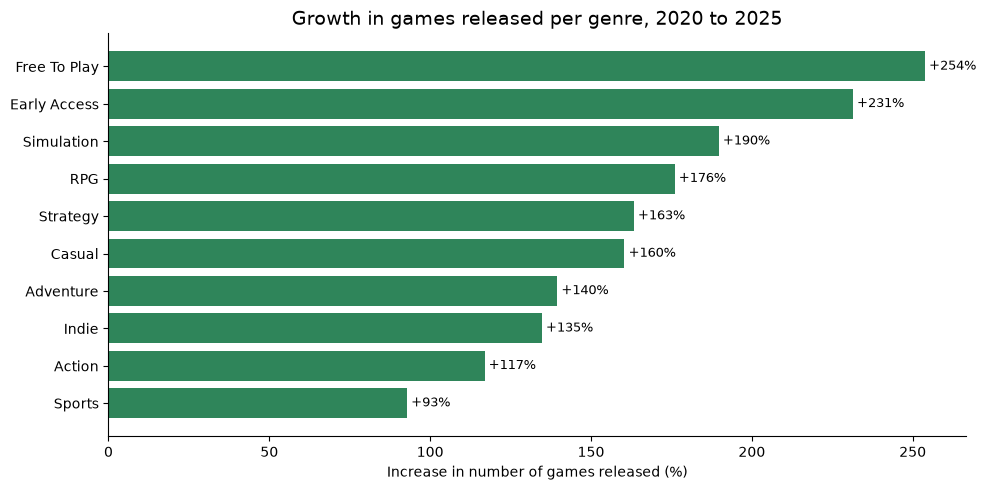

In [25]:
plot_genre_growth(growth_table)

**Player reviews by genre.** Each box shows the middle 50% of games in a genre, and the line inside it is the median. The boxes overlap a lot, so the differences between genres are small. Early Access sits slightly lower than the rest.

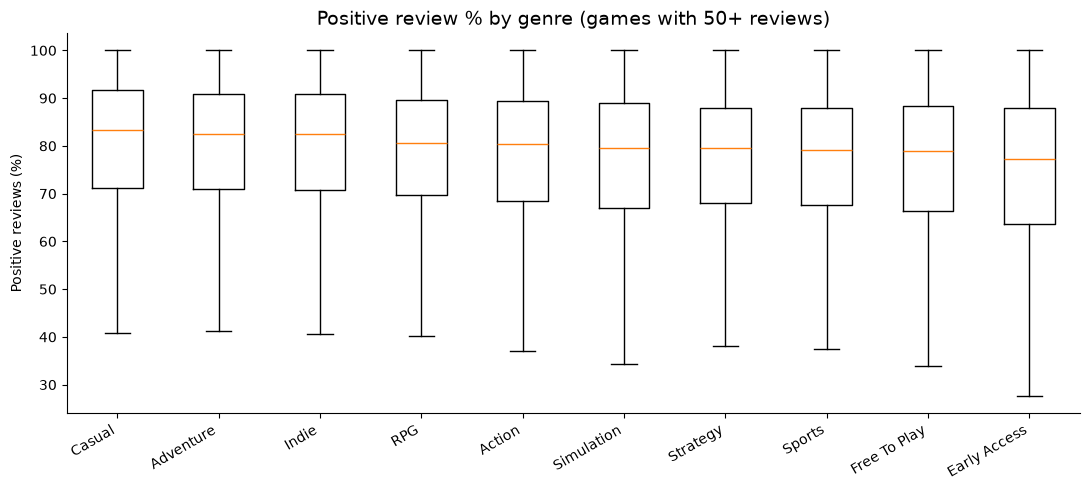

In [26]:
plot_genre_reviews(reviewed)

## Objective 3
### Explanation of Results

Objective 3 asks whether paying more gets players a better game, and whether price affects how many people buy it. Reviews are measured with the median positive of the 30,624 games with at least 50 reviews. Popularity is measured with the share of games that have 20,000 owners or higher using 101,276 games that have an owner.

**Price and reviews.** Price makes only a small difference to reviews. The median score rise from 79.2% for free games to peak of 84.7% for $5-9.99 games, then falls to 75.8% for games costing $40 or more. The Spearman correlation between price and positive % for paid games is only 0.14. Expensive games may score lower because players expect more for their money and give bad review when game falls short. However, only 132 games priced at $40+ have 50 or more reviews, so this group is small.

**Price and owners.** Among paid games there is almost no link between price and owners. Between $0.01 and $39.99 the share of games reaching 20,000 owners rises slowly from 23.3% to 28.9% before dropping to 12.9% for $40+ games.

**Free-to-play vs paid.** Free-to-play games are more likely to reach 20,000+ owners since there is no cost to try them. However, their median review score is lower so players pick up free games easily but are less happy with them. 16,704 of the 26,658 free games have no owner estimate, so the free owner figure is based on the remaining 9,954 games.

**Indie vs major publishers.** Reviews are almost identical: the median is 82.5% for indie games and 83.0% for major publishers. The real difference is reach. 84.7% of games from major publishers have 20,000+ owners, compared with only 24.0% of indie games, even though major publishers charge more. Players do not rate big-publisher games more highly, but these games sell far more copies, probably because of bigger marketing budgets and well-known series.

Overall, price does not describes quality on Steam. Mid-priced games get the best reviews and who publishes a game matters much more for how many people own it than what it costs.

### Visualisation

**Reviews by price band.** The boxes rise from Free to $5-9.99 and then fall again with $40+ games having the lowest scores.

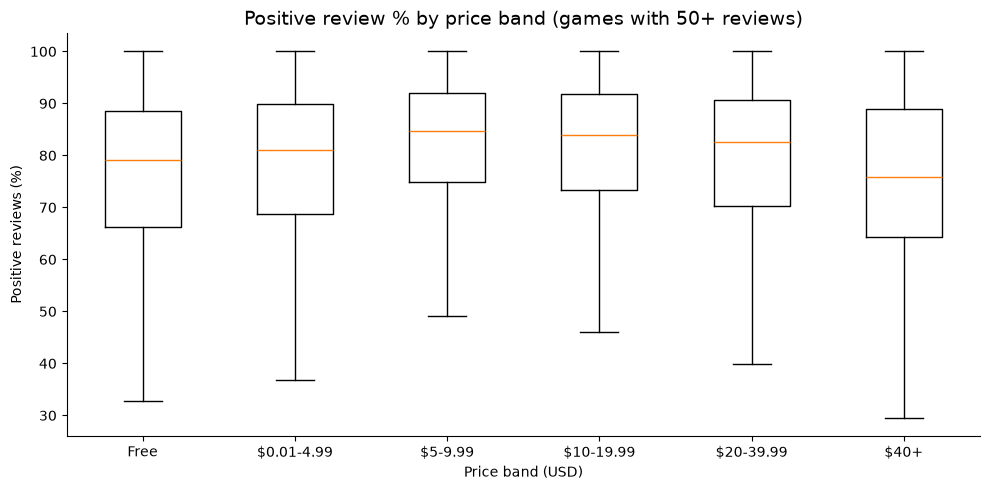

In [27]:
plot_price_band_reviews(rated)

**Owners by price band.** Free games are the most likely to reach 20,000 owners. Among paid games the share rises slowly with price up to $39.99 then drops sharply for $40+ games.

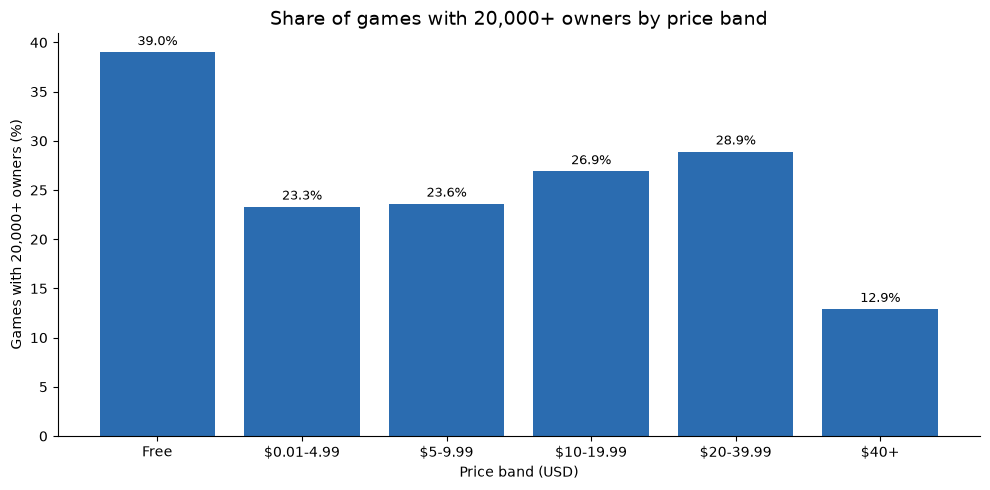

In [28]:
plot_price_band_owners(price_band_table)

**Free-to-play vs paid and indie vs major publishers.** Review scores (left) are almost the same for all four groups. The big difference is in owners (right) games from major publishers are far more likely to reach 20,000+ owners than indie games.

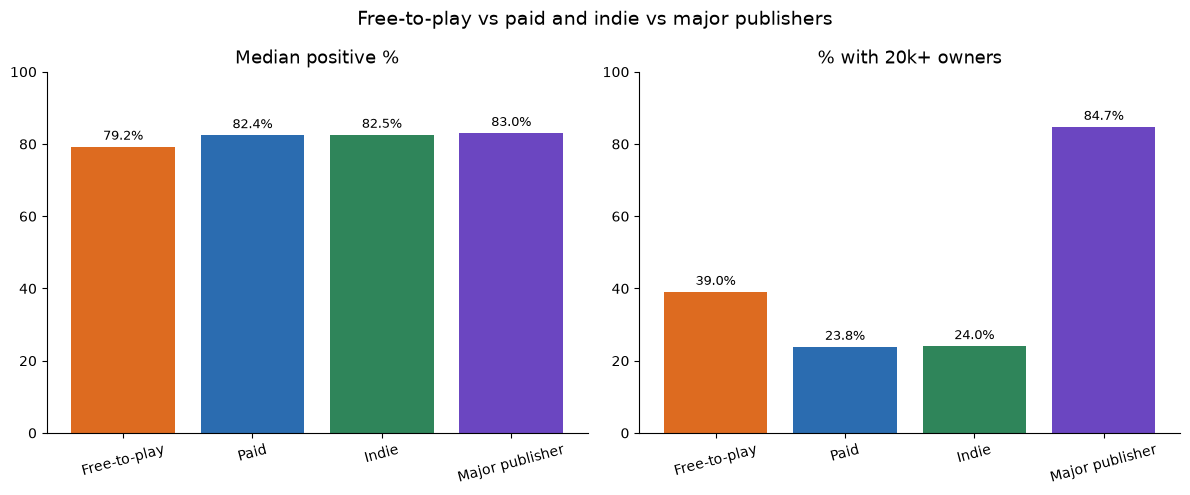

In [29]:
plot_group_comparison(free_paid_table, publisher_table)

## Objective 4 
### Explanation of Results

200-400 Words

### Visualisation

# Conclusion (5 marks)

_Your concluding section should be around 200-400 words. It is recommended
that you divide it into the following sections._

### Achievements
obj1
We cleaned the raw Steam data into one dataset of 125,855 games with 21 columns. The results show the number of games released each year grew from 10 before 2006 close to 25,000 in 2025. 

obj2

obj3
We found that price makes little difference to reviews (mid-priced \$5-19.99 games score best) and that major-publisher games are far more likely than indie games to reach 20,000+ owners, even though both are reviewed equally well.

### Limitations
obj1 The number of owners is shown as a range and not an exact figure. Many games are missing details like tags or genre and the data for 2026 only shows January to March.

obj3 The split between indie and major publishers is based on our own list of 16 large publishers, and only 132 games priced at \$40+ have 50 or more reviews, so the results for that price group are less reliable.

### Future Work

_In future work we would like to obtain more diverse data and study fridge magnets 
beyond the limited confines of student accomodation. We hypothesise that there
could be a link between fridge magnet types and social class and/or educational
achievement._